In [3]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

bands = ['delta', 'theta', 'alpha', 'beta', 'low_gamma']
metrics = ['exponent_z', 'offset_z']
all_feature_groups = bands + metrics

behavior_table = pd.read_csv('/home/hazel/shirvalkar/test-code-hazel/behavior_table_all_patients_newPC.csv')
ptIDs = ['RCS02', 'RCS03', 'RCS04', 'RCS05', 'RCS06', 'RCS07', 'RCS08', 'RCS09']

behavior_configs = {
    'nrs': {
        'column': 'nrs_z',
        'default_thresh': (50, 50),
        'patient_thresh': {
            'RCS02': (30, 30), 'RCS04': (30, 30), 'RCS03': (10, 30),
            'RCS06': (10, 10), 'RCS05': (20, 30),
        },
        'exclude_patients': [],
    },
    'mpq_affective': {
        'column': 'affective_z',
        'default_thresh': (50, 50),
        'patient_thresh': {
            'RCS02': (30, 30), 'RCS03': (5, 10), 'RCS06': (10, 10),
            'RCS07': (10, 10), 'RCS05': (20, 30),
        },
        'exclude_patients': ['RCS04', 'RCS09'],
    },
    'mpq_somatic': {
        'column': 'somatic_z',
        'default_thresh': (49, 49),
        'patient_thresh': {},
        'exclude_patients': [],
    },
    'affective_pc1': {
        'column': 'new_affective_PC1',
        'default_thresh': (50, 50),
        'patient_thresh': {},
        'exclude_patients': [],
    },
    'sensory_pc1': {
        'column': 'new_sensory_PC1',
        'default_thresh': (50, 50),
        'patient_thresh': {},
        'exclude_patients': [],
    },
}

In [4]:
def split_dep_new(series, percent1, percent2=None):
    if percent2 is None:
        percent2 = percent1
    X = np.asarray(series)
    labels = pd.Series(['neutral'] * len(X), index=series.index)
    thresh_low = np.percentile(X, percent1)
    thresh_high = np.percentile(X, 100 - percent2)
    low = np.where(X <= thresh_low)[0]
    high = np.where(X >= thresh_high)[0]
    labels.iloc[high] = 'high'
    labels.iloc[low] = 'low'
    return labels, len(high), len(np.where((X > thresh_low) & (X < thresh_high))[0]), len(low)

def parse_metric_feat_name(name, metrics):
    for m in sorted(metrics, key=len, reverse=True):
        prefix = m + '_'
        if name.startswith(prefix):
            ch_label = name[len(prefix):]
            roi = re.sub(r'_\d+$', '', ch_label)
            return m, roi, ch_label
    raise ValueError(f"Feature name doesn't match any known band/metric: {name}")

In [5]:
def build_channel_level_features(ptID, behavior_table, feature_type, behavior_key, config,
                                 r2_thresh=0.9):
    if ptID in config['exclude_patients']:
        return None
    subset = behavior_table[behavior_table['ptID'] == ptID].copy()
    thresh_low, thresh_high = config['patient_thresh'].get(ptID, config['default_thresh'])
    label, _, _, _ = split_dep_new(subset[config['column']], thresh_low, thresh_high)
    subset['behavior_label'] = label

    records_df = pd.read_pickle(f"/home/hazel/shirvalkar/pain-data/Stage1-test/{ptID}/records_df_fooof_{ptID}.pkl")
    feat_df = pd.read_csv('/home/hazel/shirvalkar/test-code-hazel/perchannel_psdfeat_and_aperiodic_df.csv')
    feat_df = feat_df[feat_df['ptID'] == ptID]

    merged = records_df.merge(subset, on='trial_idx', suffixes=('', '_dup')) \
                       .merge(feat_df, on=['trial_idx', 'ch_label'], suffixes=('', '__dup'))
    merged = merged[[c for c in merged.columns if not c.endswith('_dup')]]
    merged_filt = merged[(merged['r2'] >= r2_thresh) & (merged['behavior_label'] != 'neutral')]
    if merged_filt.empty:
        return None

    values = bands if feature_type == 'periodic' else metrics
    wide = merged_filt.pivot_table(index='trial_idx', columns='ch_label', values=values)
    wide.columns = [f'{v}_{ch}' for v, ch in wide.columns]

    if wide.shape[1] == 0:
        return None
    tidx = pd.Series(wide.index.values, name='trial_idx')
    y = (merged_filt.drop_duplicates('trial_idx').set_index('trial_idx')
                    .loc[wide.index, 'behavior_label'])
    print(f'{ptID}: {wide.shape[1]} features, {len(wide)} trials, '
          f'{wide.isna().to_numpy().mean():.1%} missing, high/low = {(y == "high").sum()}/{(y == "low").sum()}')
    return wide.reset_index(drop=True), y.reset_index(drop=True), tidx

In [6]:
def align_pca_sign(pca, reference_components):
    aligned = pca.components_.copy()
    for i in range(aligned.shape[0]):
        if np.dot(aligned[i], reference_components[i]) < 0:
            aligned[i] = -aligned[i]
    return aligned
def coef_toward_high(lr, pos='high'):
    return lr.coef_.ravel() * (1 if lr.classes_[1] == pos else -1)

def to_feature_space(clf, ref_components, lr_name):
    b = coef_toward_high(clf.named_steps[lr_name])
    if 'pca' in clf.named_steps:
        b = align_pca_sign(clf.named_steps['pca'], ref_components).T @ b
    return b

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV

def build_clf(n_components, C=None):
    steps = [SimpleImputer(strategy='mean'), StandardScaler()]
    if n_components != 0:
        steps.append(PCA(n_components=n_components, random_state=42))
    if C is None:
        steps.append(LogisticRegressionCV(
            penalty='l2', solver='liblinear', cv=5, random_state=42,
            Cs=10, scoring='roc_auc', max_iter=1000))
    else:
        steps.append(LogisticRegression(
            penalty='l2', solver='liblinear', C=C, max_iter=1000))
    return make_pipeline(*steps)

In [7]:
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import seaborn as sns
import os, json, datetime
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_score, recall_score, f1_score

def plot_confusion_matrix(y, oof_pred, fold_scores, title, n_splits = 5, labels=["high", "low"],n_boot=1, savedir=None):
    cm = confusion_matrix(y, oof_pred, labels=labels)/n_boot
    tn_fp_fn_tp = None  # not used; extract counts by the chosen label order
    tp = cm[0, 0]
    fn = cm[0, 1]
    fp = cm[1, 0]
    tn = cm[1, 1]
    precision = precision_score(y, oof_pred, pos_label='high', zero_division=0)
    recall = recall_score(y, oof_pred, pos_label='high', zero_division=0)
    f1 = f1_score(y, oof_pred, pos_label='high', zero_division=0)
    annotations = np.array([
        [f"TP\nn= {tp}", f"FN\nn= {fn}"],
        [f"FP\nn= {fp}", f"TN\nn= {tn}"]
    ])
    fig, ax = plt.subplots(figsize=(6, 6))
    sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', cbar=False,
                xticklabels=["high", "low"], yticklabels=["high", "low"])
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    ax.text(0.5, -0.1, f"Positive class = high\n{n_splits}CV Mean AUC: {fold_scores.mean():.3f}\nPrecision: {precision:.3f}, Recall: {recall:.3f}, F1-score: {f1:.3f}",
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=10)
    plt.title(f"{title}: Pooled OOF confusion matrix")
    plt.tight_layout()
    if savedir:
        plt.savefig(f"{savedir}/{title}_OOF_confusion_matrix.png", dpi=300, bbox_inches='tight')
    plt.show()

In [8]:
def pooled_pca_logistic_stability(X, y, groups, behavior_label, feature_type_label, pt=None,
                                  n_components=5, n_splits=5, random_state=42, savepath=False,
                                  bootstrap=False, n_boot=1, records=None):          # CHANGED: +records
    clf_full = build_clf(n_components)
    clf_full.fit(X, y)
    full_C = float(clf_full.named_steps['logisticregressioncv'].C_[0])                 # NEW
    pca_evr = clf_full.named_steps['pca'].explained_variance_ratio_ if n_components != 0 else None    # NEW
    ref_components = clf_full.named_steps['pca'].components_ if n_components != 0 else None   # NEW

    rng = np.random.RandomState(random_state)
    if bootstrap:
        print(f"bootstrap n={n_boot}, num_trial={int(groups.value_counts().median())}\n")
        bs = []
        for _ in range(n_boot):
            bi = balanced_bootstrap_idx(groups, y, int(groups.value_counts().median()), rng)
            clf = build_clf(n_components, full_C).fit(X.iloc[bi], y.iloc[bi])
            bs.append(to_feature_space(clf, ref_components, 'logisticregression'))     # CHANGED
        full_sample_coef = np.mean(bs, axis=0)
    else:
        
        full_sample_coef = to_feature_space(clf_full, ref_components, 'logisticregressioncv')   # CHANGED

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_scores = []
    fold_coefs = []
    oof_proba = np.full(len(y), np.nan)
    oof_pred = np.empty(len(y), dtype=object)
    boot_true, boot_pred = [], []
    patient_compositions = []
    patient_order = sorted(groups.dropna().unique())
    fold_records = []                                                                   # NEW

    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y)):                   # CHANGED: enumerate
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        group_train, group_test = groups.iloc[train_idx], groups.iloc[test_idx]

        if bootstrap:
            rec = {}                                                                    # NEW
            auc, beta_fold, yt, yp = fit_eval_balanced_bootstrap(
                X_train, y_train, group_train, X_test, y_test, group_test, n_components, n_boot, rng,
                ref_components=ref_components, record=rec)                              # CHANGED
            fold_scores.append(auc)
            fold_coefs.append(beta_fold)
            boot_true.append(yt)
            boot_pred.append(yp)
        else:
            train_counts = group_train.value_counts(normalize=True).reindex(patient_order, fill_value=0) * 100
            test_counts = group_test.value_counts(normalize=True).reindex(patient_order, fill_value=0) * 100
            patient_compositions.append((train_counts, test_counts))

            clf_fold = build_clf(n_components)
            clf_fold.fit(X_train, y_train)
            y_proba = clf_fold.predict_proba(X_test)
            pos_idx = list(clf_fold.classes_).index('high')
            auc = roc_auc_score((y_test == 'high').astype(int), y_proba[:, pos_idx])
            fold_scores.append(auc)
            oof_proba[test_idx] = y_proba[:, pos_idx]
            oof_pred[test_idx] = clf_fold.predict(X_test)

            beta_fold = to_feature_space(clf_fold, ref_components, 'logisticregressioncv')   # CHANGED
            fold_coefs.append(beta_fold)

            rec = dict(C=float(clf_fold.named_steps['logisticregressioncv'].C_[0]),     # NEW
                       n_per_pt_train=np.nan, n_per_pt_test=np.nan,
                       n_train_boot=len(train_idx), n_test_boot=len(test_idx),
                       n_drawn_train=np.ones(len(train_idx)), n_drawn_test=np.ones(len(test_idx)),
                       n_pred_high=(oof_pred[test_idx] == 'high').astype(float),
                       sum_proba_high=y_proba[:, pos_idx])

        fold_records.append(dict(rec, fold=fold_idx, auc=auc, coef=beta_fold,           # NEW
                                 train_idx=train_idx, test_idx=test_idx))

    fold_scores = np.array(fold_scores)
    fold_coefs = np.array(fold_coefs)

    print(f'{behavior_label}_{feature_type_label} pooled model — out-of-sample AUC ({n_splits}KFold): {fold_scores.mean():.3f} ± {fold_scores.std():.3f}')

    coef_mean = fold_coefs.mean(axis=0)
    coef_std = fold_coefs.std(axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        coef_snr = coef_mean / coef_std
    sign_consistency = abs(sum(fold_coefs>=0)-sum(fold_coefs<=0))/fold_coefs.shape[0]
    print(sign_consistency)

    stability_df = pd.DataFrame({
        'feature_type': feature_type_label,
        'feature': X.columns,
        'full_sample_coef': full_sample_coef,
        'cv_mean_coef': coef_mean,
        'cv_std_coef': coef_std,
        'cv_snr': coef_snr,
        'sign_consistency': sign_consistency
    })
    stability_df['roi'] = [s.split('_')[-1] for s in stability_df['feature']]
    stability_df['feature_group'] = [re.match(r'^[a-z_]*', s).group()[:-1] for s in stability_df['feature']]

    if records is not None:                                                             # NEW
        records.update(folds=fold_records, full_C=full_C, full_sample_coef=full_sample_coef, pca_evr=pca_evr if n_components != 0 else None,
                       bootstrap=bootstrap, n_boot=(n_boot if bootstrap else 1), n_splits=n_splits)

    # from pathlib import Path
    # if bootstrap:
    #     y_eval, pred_eval = np.concatenate(boot_true), np.concatenate(boot_pred)
    #     savedir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/bootstrap/confusion-matrix'
    #     plot_confusion_matrix(y_eval, pred_eval, fold_scores, title=f'{behavior_label}_{feature_type_label}_pooled_boot{n_boot}', n_boot=n_boot, savedir=savedir)
    # else:
    #     if pt == None:
    #         savedir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/confusion-matrix'
    #         Path(savedir).mkdir(exist_ok=True)
    #     else:
    #         savedir = f'/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/confusion-matrix/individual-pt/{pt}'
    #         Path(savedir).mkdir(parents=True, exist_ok=True)
    #     plot_confusion_matrix(y, oof_pred, fold_scores, title=f'{behavior_label}_{feature_type_label}_pooled', savedir=savedir)

    return stability_df, fold_scores

In [9]:
import re
from pathlib import Path

def individual_decoding_channel_level(behavior_key, feature_type, n_components=5, n_splits=5,random_state=42):
    config = behavior_configs[behavior_key]
    ids = dict(behavior=behavior_key, feature_type=feature_type)
    pt_rows, fold_rows, trial_parts, coef_parts, summ_parts = [], [], [], [], []

    for pt in ptIDs:
        out = build_channel_level_features(pt, behavior_table, feature_type, behavior_key, config)
        if out is None:
            continue
        Xp, yp, tidx = out
        gp = pd.Series(pt, index=yp.index)

        rec = {}
        stab_df, fold_scores = pooled_pca_logistic_stability(
            Xp, yp, gp, behavior_key, feature_type, pt=pt, n_components=n_components, n_splits=n_splits,
            random_state=random_state, records=rec)

        parsed = pd.DataFrame([parse_metric_feat_name(f, all_feature_groups) for f in Xp.columns],
                              columns=['feature_group', 'roi', 'ch_label'], index=Xp.columns)
        stab = (stab_df.drop(columns=['roi', 'feature_group'], errors='ignore').join(parsed, on='feature'))
        stab.insert(0, 'ptID', pt); stab.insert(1, 'behavior', behavior_key)
        summ_parts.append(stab)

        score = (behavior_table.loc[behavior_table.ptID == pt, ['trial_idx', config['column']]]
                 .rename(columns={config['column']: 'raw_score'}))
        base = pd.DataFrame({'row_idx': np.arange(len(Xp)), 'trial_idx': tidx.values, 'label': yp.values}
                            ).merge(score, on='trial_idx', how='left')
        base.insert(0, 'ptID', pt)

        for f in rec['folds']:
            k, tr, te = f['fold'], f['train_idx'], f['test_idx']
            ytr, yte = yp.iloc[tr], yp.iloc[te]
            fold_rows.append(dict(ptID=pt, **ids, fold=k, n_train=len(tr), n_test=len(te),
                                  n_train_high=int((ytr == 'high').sum()), n_train_low=int((ytr == 'low').sum()),
                                  n_test_high=int((yte == 'high').sum()), n_test_low=int((yte == 'low').sum()),
                                  C=f['C'], auc=f['auc']))
            part = base.iloc[te].copy()
            part['fold'] = k
            part['pred_proba_high'] = f['sum_proba_high']
            part['pred_label'] = np.where(f['n_pred_high'] > 0.5, 'high', 'low')
            trial_parts.append(part.assign(**ids))
            coef_parts.append(pd.DataFrame({'ptID': pt, **ids, 'fold': k, 'feature': Xp.columns,
                                            'coef': f['coef']}).join(parsed, on='feature'))
        fold_rows.append(dict(ptID=pt, **ids, fold=-1, n_train=len(Xp), C=rec['full_C'], auc=np.nan))   # 全数据拟合
        coef_parts.append(pd.DataFrame({'ptID': pt, **ids, 'fold': -1, 'feature': Xp.columns,
                                        'coef': rec['full_sample_coef']}).join(parsed, on='feature'))

        evr = rec['pca_evr']
        pt_rows.append(dict(ptID=pt, **ids, n_trials=len(Xp), n_high=int((yp == 'high').sum()),
                            n_low=int((yp == 'low').sum()), n_features=Xp.shape[1],
                            n_channels=parsed['ch_label'].nunique(), n_rois=parsed['roi'].nunique(),
                            missing_frac=float(Xp.isna().to_numpy().mean()), n_components=n_components, n_splits=n_splits,
                            pca_evr=None if evr is None else [float(v) for v in evr],
                            pca_cum_var=np.nan if evr is None else float(evr.sum()),
                            auc_mean=float(fold_scores.mean()), auc_sd=float(fold_scores.std()),
                            C_geomean=float(10 ** np.log10([f['C'] for f in rec['folds']]).mean())))

    return dict(patient_table=pd.DataFrame(pt_rows), fold_table=pd.DataFrame(fold_rows),
                trial_table=pd.concat(trial_parts, ignore_index=True),
                coef_table=pd.concat(coef_parts, ignore_index=True),         # 每折反投影后的系数,fold=-1 是全数据拟合
                coef_summary=pd.concat(summ_parts, ignore_index=True))       # full_sample_coef / cv_mean_coef / cv_std / snr / sign_consistency

def save_individual_metadata(outdir, tables, behavior_key, feature_type, settings=None):
    Path(outdir).mkdir(parents=True, exist_ok=True)
    pd.to_pickle({**tables, 'settings': settings}, f'{outdir}/{behavior_key}_{feature_type}_individual.pickle')

def load_individual_metadata(outdir):
    out = {}
    for p in sorted(Path(outdir).glob('*_individual.pickle')):
        d = pd.read_pickle(p)
        for k, v in d.items():
            if isinstance(v, pd.DataFrame):
                out.setdefault(k, []).append(v)
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from sklearn.metrics import confusion_matrix

C_HIGH, C_LOW, C_NEUTRAL = '#E74C3C', '#3498DB', '#D9D9D9'
BAND_ORDER = ['delta', 'theta', 'alpha', 'beta', 'low_gamma', 'exponent_z', 'offset_z']

def _roi_key(r):
    side, _, area = str(r).partition(' ')
    return ({'L': 0, 'R': 1}.get(side, 2), area)

def _ch_num(ch):
    m = re.search(r'_(\d+)$', str(ch)); return int(m.group(1)) if m else 0

def _cutoffs(pt, config, bt):
    tl, th = config['patient_thresh'].get(pt, config['default_thresh'])
    x = np.asarray(bt.loc[bt['ptID'] == pt, config['column']])
    return np.percentile(x, tl), np.percentile(x, 100 - th)

def plot_patient_overview(tables, behavior_key, feature_type, behavior_table, config,
                          sort_by=None, ascending=False, stable_thresh=0.6, coef_scale='patient',
                          bins=20, row_h=2.7, c_range=(-4, 4), savedir=None, show=True):
    sel = lambda d: d[(d.behavior == behavior_key) & (d.feature_type == feature_type)]
    P, F, T, S = (sel(tables[k]) for k in ['patient_table', 'fold_table', 'trial_table', 'coef_summary'])
    if sort_by is not None:
        P = P.sort_values(sort_by, ascending=ascending)
    pts, nr = P['ptID'].tolist(), len(P)
    cmapC, normC = plt.get_cmap('viridis'), Normalize(*c_range)
    cm_coef = plt.get_cmap('RdBu_r').copy(); cm_coef.set_bad('#EEEEEE')

    def lim_of(v):
        v = np.abs(np.asarray(v, float)); v = v[np.isfinite(v)]
        return (np.percentile(v, 99) if len(v) else 1.0) or 1.0
    glob_lim = lim_of(S['cv_mean_coef'])

    fig_w, fig_h = 32, row_h * nr + 2.0
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = fig.add_gridspec(nr, 7, width_ratios=[2.3, 2.5, 2.6, 2.0, 2.4, 1.9, 7.0], hspace=.8, wspace=.35,
                          left=.02, right=.995, top=1 - 1.0 / fig_h, bottom=1.3 / fig_h)
    titles = ['Patient', 'Raw score (gray = all trials)', 'AUC per fold  (number = log10 C)',
              'OOF confusion (row % = recall)', 'OOF P(high) by true label', 'PCA variance explained',
              'Coefficient (+ → high);  dot = sign stable across folds']

    for r, pt in enumerate(pts):
        p = P[P.ptID == pt].iloc[0]; f_ = F[(F.ptID == pt) & (F.fold >= 0)].sort_values('fold')
        t, s = T[T.ptID == pt], S[S.ptID == pt]
        ax = [fig.add_subplot(gs[r, c]) for c in range(7)]
        if r == 0:
            for a, ti in zip(ax, titles):
                a.set_title(ti, fontsize=10, fontweight='bold')

        # 1. 基本信息
        a = ax[0]; a.set_xlim(0, 1); a.set_ylim(0, 1); a.axis('off')
        a.text(0, .98, pt, fontsize=15, fontweight='bold', va='top')
        info = [f"trials  {p.n_trials}", f"features  {p.n_features}  ({p.n_channels} ch, {p.n_rois} ROIs)",
                f"missing  {p.missing_frac:.1%}",
                f"PCA  {p.n_components} PCs,  {p.pca_cum_var:.0%} var" if p.pca_evr is not None else "no PCA",
                f"{p.n_splits}-fold AUC  {p.auc_mean:.3f} ± {p.auc_sd:.3f}",
                f"C (geo-mean)  10^{np.log10(p.C_geomean):.1f}"]
        for i, line in enumerate(info):
            a.text(0, .80 - i * .115, line, fontsize=9.5, va='top')
        fh = p.n_high / p.n_trials
        a.barh(.06, fh, height=.1, color=C_HIGH); a.barh(.06, 1 - fh, left=fh, height=.1, color=C_LOW)
        a.text(fh / 2, .06, f'high {p.n_high}', ha='center', va='center', color='white', fontsize=8, fontweight='bold')
        a.text(fh + (1 - fh) / 2, .06, f'low {p.n_low}', ha='center', va='center', color='white', fontsize=8, fontweight='bold')

        # 2. raw score
        allv = behavior_table.loc[behavior_table.ptID == pt, config['column']].dropna().values
        edges = np.linspace(allv.min(), allv.max(), bins + 1)
        ax[1].hist(allv, bins=edges, color=C_NEUTRAL)
        for lab, col in [('low', C_LOW), ('high', C_HIGH)]:
            ax[1].hist(t.loc[t.label == lab, 'raw_score'].dropna(), bins=edges, color=col, alpha=.85)
        lo, hi = _cutoffs(pt, config, behavior_table)
        ax[1].axvline(lo, color=C_LOW, ls='--', lw=1.2); ax[1].axvline(hi, color=C_HIGH, ls='--', lw=1.2)
        ax[1].set_yticks([]); ax[1].tick_params(labelsize=8)

        # 3. 每折 AUC,颜色 = log10 C
        logC = np.log10(f_['C'].to_numpy())
        ax[2].bar(f_['fold'], f_['auc'], color=[cmapC(normC(v)) for v in logC], edgecolor='k', lw=.4)
        for k_, a_, l_ in zip(f_['fold'], f_['auc'], logC):
            ax[2].annotate(f'{l_:.1f}', (k_, a_), xytext=(0, 2), textcoords='offset points',
                           ha='center', va='bottom', fontsize=7.5)
        ax[2].axhline(.5, ls=':', c='gray'); ax[2].axhline(p.auc_mean, ls='--', c='k', lw=1)
        ax[2].set_ylim(0, 1.12); ax[2].set_xticks(f_['fold']); ax[2].set_xlabel('fold', fontsize=8)
        ax[2].tick_params(labelsize=8)

        # 4. 混淆矩阵(5 折 out-of-fold 合并)
        cm = confusion_matrix(t['label'], t['pred_label'], labels=['high', 'low'])
        rs = cm.sum(axis=1, keepdims=True)
        pct = np.divide(cm, rs, out=np.zeros(cm.shape, float), where=rs > 0)
        ax[3].imshow(pct, cmap='Blues', vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax[3].text(j, i, f'{cm[i, j]}\n{pct[i, j]:.0%}', ha='center', va='center', fontsize=10,
                           color='white' if pct[i, j] > .6 else 'black')
        ax[3].set_xticks([0, 1]); ax[3].set_xticklabels(['pred high', 'pred low'], fontsize=8)
        ax[3].set_yticks([0, 1]); ax[3].set_yticklabels(['true high', 'true low'], fontsize=8)
        ax[3].set_xlabel(f'balanced acc {np.mean(np.diag(pct)):.2f}', fontsize=8.5)

        # 5. 预测概率分布
        pe = np.linspace(0, 1, 16)
        for lab, col in [('low', C_LOW), ('high', C_HIGH)]:
            ax[4].hist(t.loc[t.label == lab, 'pred_proba_high'], bins=pe, color=col, alpha=.6)
        ax[4].axvline(.5, ls=':', c='k'); ax[4].set_xlim(0, 1); ax[4].set_yticks([]); ax[4].tick_params(labelsize=8)
        ax[4].set_xlabel('P(high)', fontsize=8)

        # 6. PCA 方差
        if p.pca_evr is not None:
            evr = np.asarray(p.pca_evr); x = np.arange(1, len(evr) + 1)
            ax[5].bar(x, evr, color='#446F85'); ax[5].plot(x, np.cumsum(evr), 'o-', color='k', ms=3, lw=1)
            for xi, c_ in zip(x, np.cumsum(evr)):
                ax[5].annotate(f'{c_:.0%}', (xi, c_), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=7)
            ax[5].set_ylim(0, max(np.cumsum(evr)) * 1.25); ax[5].set_xticks(x)
            ax[5].set_xticklabels([f'PC{i}' for i in x], fontsize=7.5); ax[5].tick_params(labelsize=8)
        else:
            ax[5].axis('off')

        # 7. 系数热图
        pairs = sorted(set(zip(s['ch_label'], s['roi'])), key=lambda q: (_roi_key(q[1]), _ch_num(q[0])))
        cols, rois = [q[0] for q in pairs], [q[1] for q in pairs]
        groups = [g for g in BAND_ORDER if g in set(s['feature_group'])]
        pv = lambda v: (s.pivot_table(index='feature_group', columns='ch_label', values=v, aggfunc='mean')
                          .reindex(index=groups, columns=cols))
        M, SC = pv('cv_mean_coef'), pv('sign_consistency')
        lim = glob_lim if coef_scale == 'global' else lim_of(M.to_numpy())
        ax[6].imshow(M.values, cmap=cm_coef, vmin=-lim, vmax=lim, aspect='auto', interpolation='none')
        yy, xx = np.where(SC.values >= stable_thresh)
        ax[6].scatter(xx, yy, s=6, c='k', zorder=3)
        ax[6].set_yticks(range(len(groups))); ax[6].set_yticklabels([g.replace('_z', '') for g in groups], fontsize=8)
        bounds = [i for i in range(1, len(rois)) if rois[i] != rois[i - 1]]
        for bd in bounds:
            ax[6].axvline(bd - .5, color='k', lw=.7)
        st, en = [0] + bounds, bounds + [len(rois)]
        ax[6].set_xticks([(a_ + b_ - 1) / 2 for a_, b_ in zip(st, en)])
        ax[6].set_xticklabels([rois[a_] for a_ in st], rotation=60, ha='right', fontsize=6.5)
        ax[6].tick_params(length=0, pad=2)
        if coef_scale != 'global':
            ax[6].text(1, 1.03, f'color ±{lim:.2g}', transform=ax[6].transAxes, ha='right', fontsize=7.5, color='dimgray')
        for sp in ax[6].spines.values():
            sp.set_visible(False)

    # 颜色条和图例
    c1 = fig.add_axes([.08, .35 / fig_h, .13, .14 / fig_h])
    fig.colorbar(ScalarMappable(norm=normC, cmap=cmapC), cax=c1, orientation='horizontal')
    c1.set_xlabel('log10 C  (left = strong regularization)', fontsize=8); c1.tick_params(labelsize=7)
    if coef_scale == 'global':
        c2 = fig.add_axes([.58, .35 / fig_h, .13, .14 / fig_h])
        fig.colorbar(ScalarMappable(norm=Normalize(-glob_lim, glob_lim), cmap=cm_coef), cax=c2, orientation='horizontal')
        c2.set_xlabel('coefficient (+ → high)', fontsize=8); c2.tick_params(labelsize=7)
    fig.legend(handles=[Patch(color=C_HIGH, label='high'), Patch(color=C_LOW, label='low'),
                        Patch(color=C_NEUTRAL, label='all trials / neutral')],
               loc='lower center', ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(.38, 0))
    p0 = P.iloc[0]
    fig.suptitle(f'{behavior_key} — {feature_type}  |  individual channel-level models  '
                 f'(PCA {int(p0.n_components)}, {int(p0.n_splits)}-fold CV)', fontsize=14, y=.995)
    if savedir:
        Path(savedir).mkdir(parents=True, exist_ok=True)
        fig.savefig(f'{savedir}/{behavior_key}_{feature_type}_patient_overview.png', dpi=200, bbox_inches='tight')
    plt.show() if show else plt.close(fig)
    return fig

RCS02: 190 features, 54 trials, 3.5% missing, high/low = 28/26
nrs_periodic pooled model — out-of-sample AUC (5KFold): 0.927 ± 0.077
[0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.6 0.6 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.6 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.6 0.2 0.2 0.6 0.6 0.2 0.6 0.2 0.2
 0.2 0.2 0.6 0.6 0.2 0.2 1.  0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.6 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.6 0.2
 0.6 0.2 0.6 0.2 0.6 0.6 0.2 0.6 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.2
 0.2 0.6 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.2 0.2]
RCS03: 135 features, 58 trials, 4.1% missing, high/low = 37/21
nrs_periodic pooled model — out-

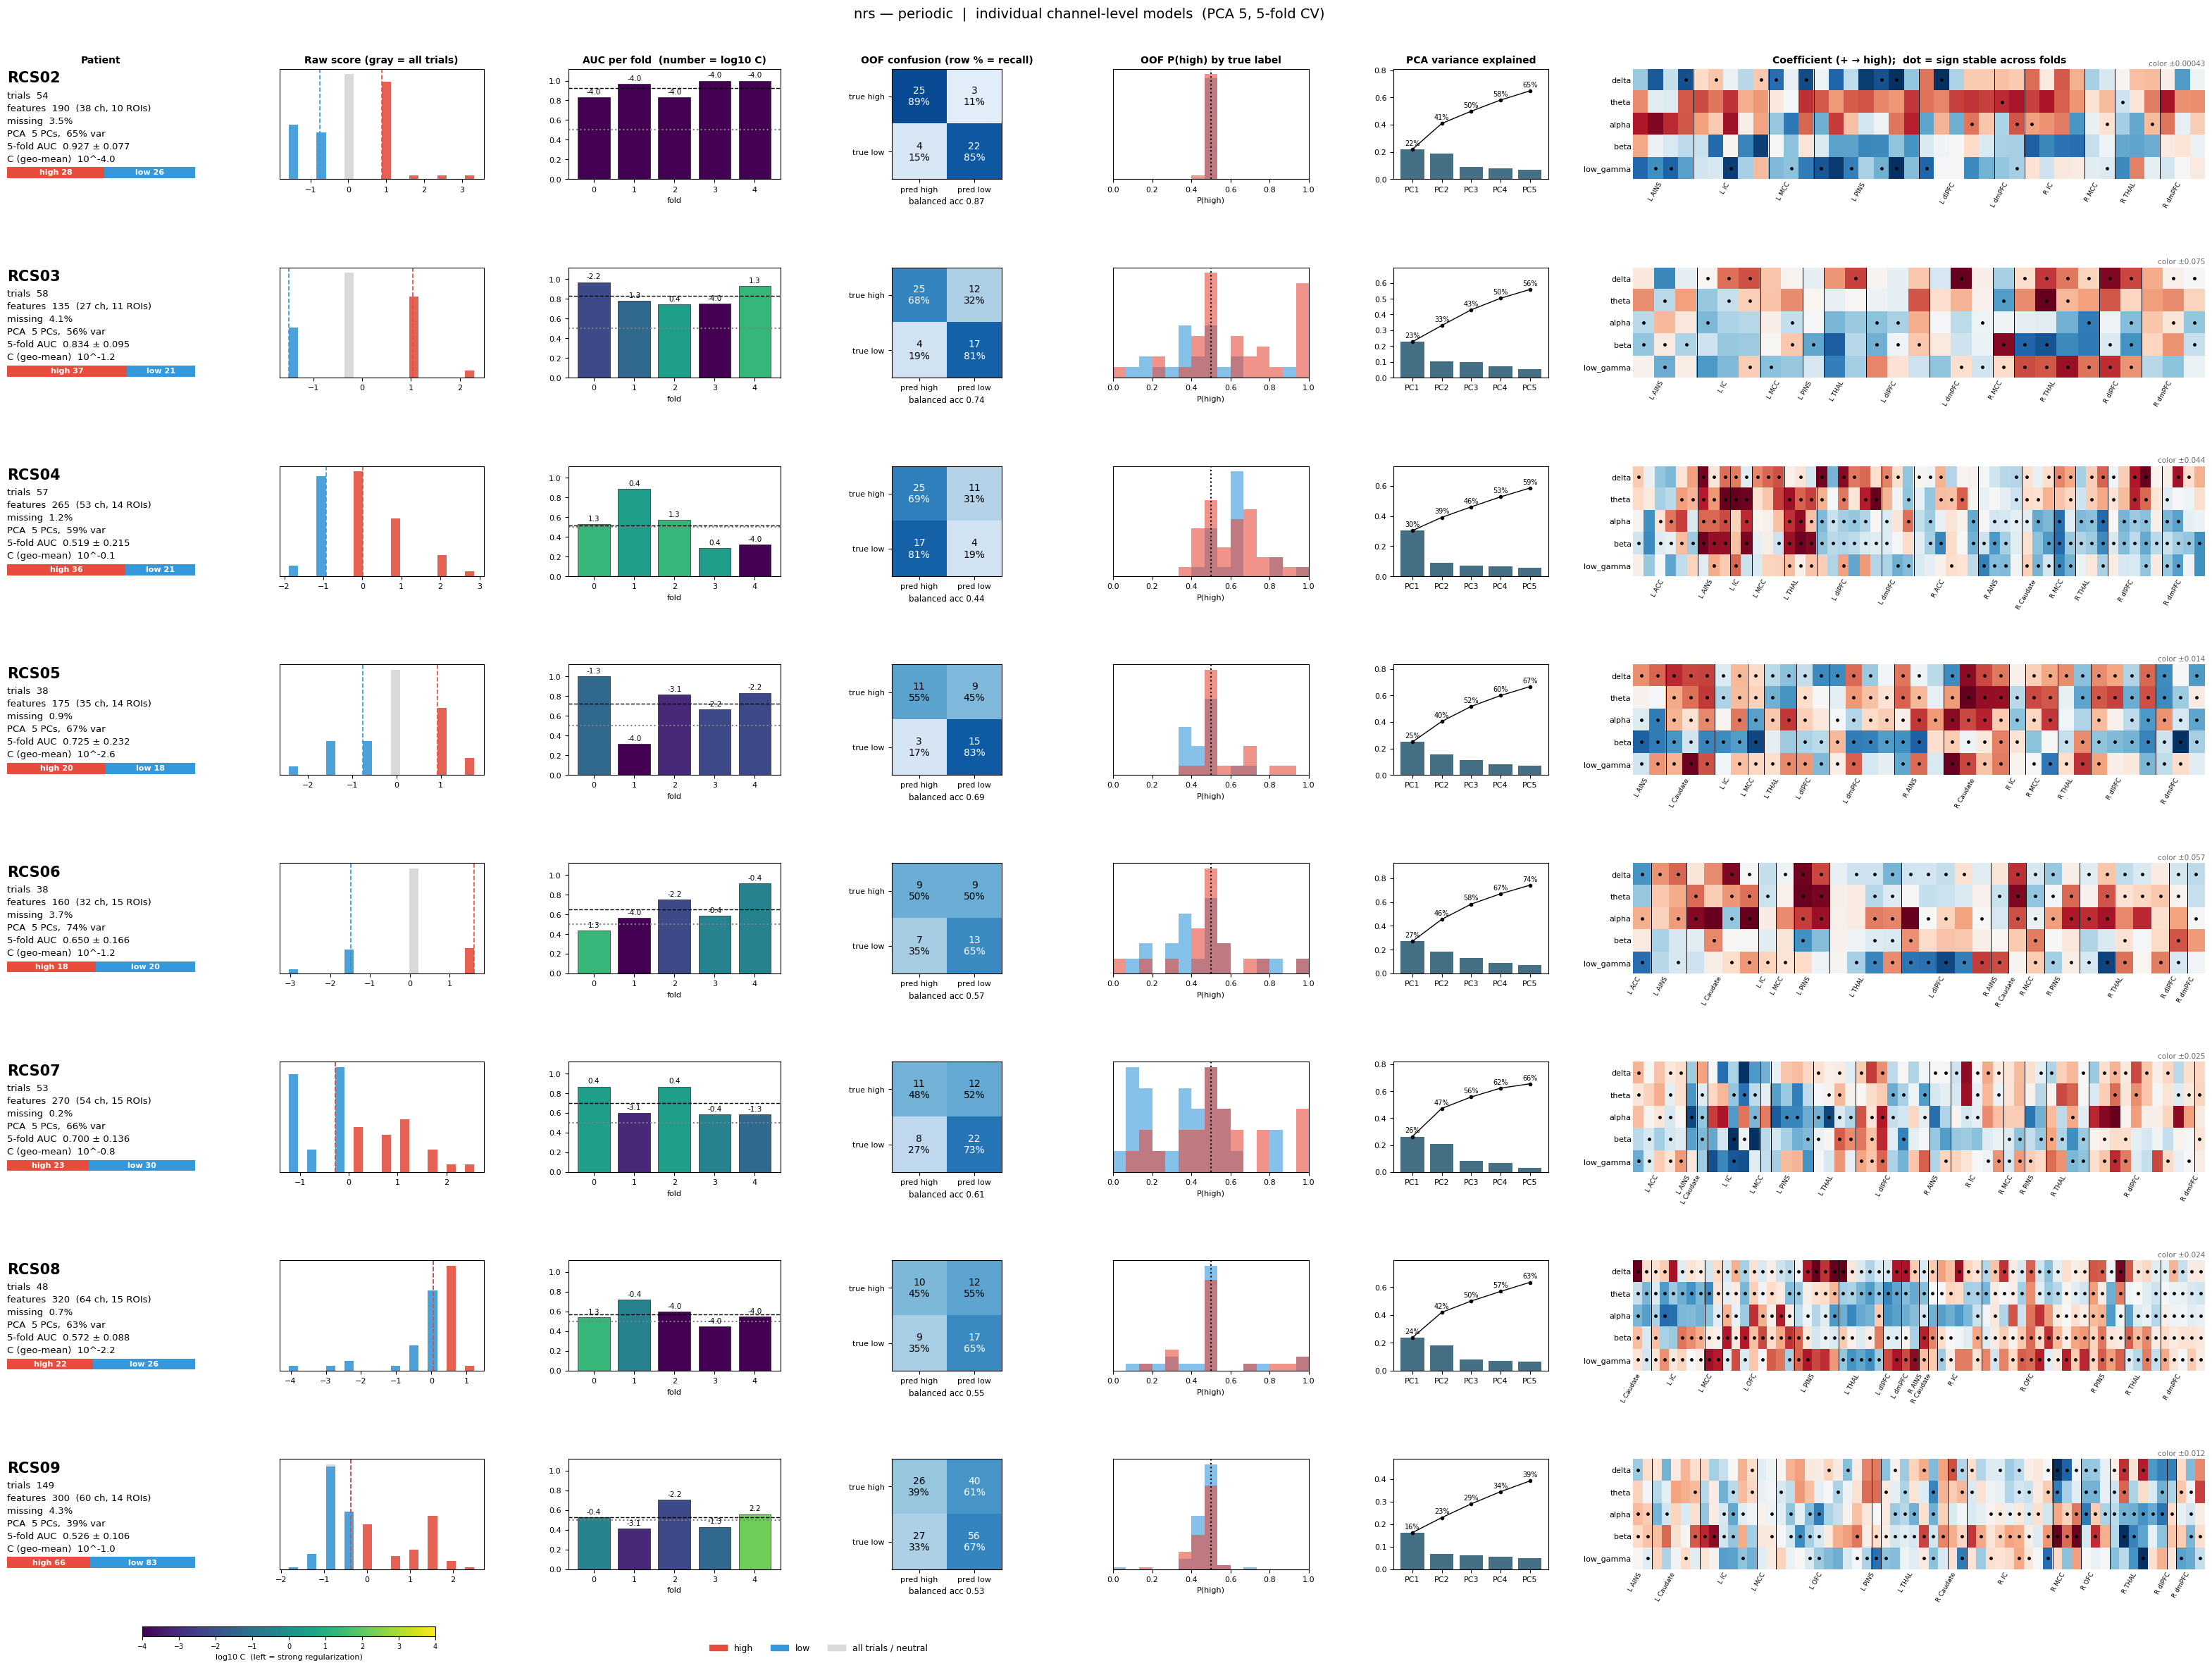

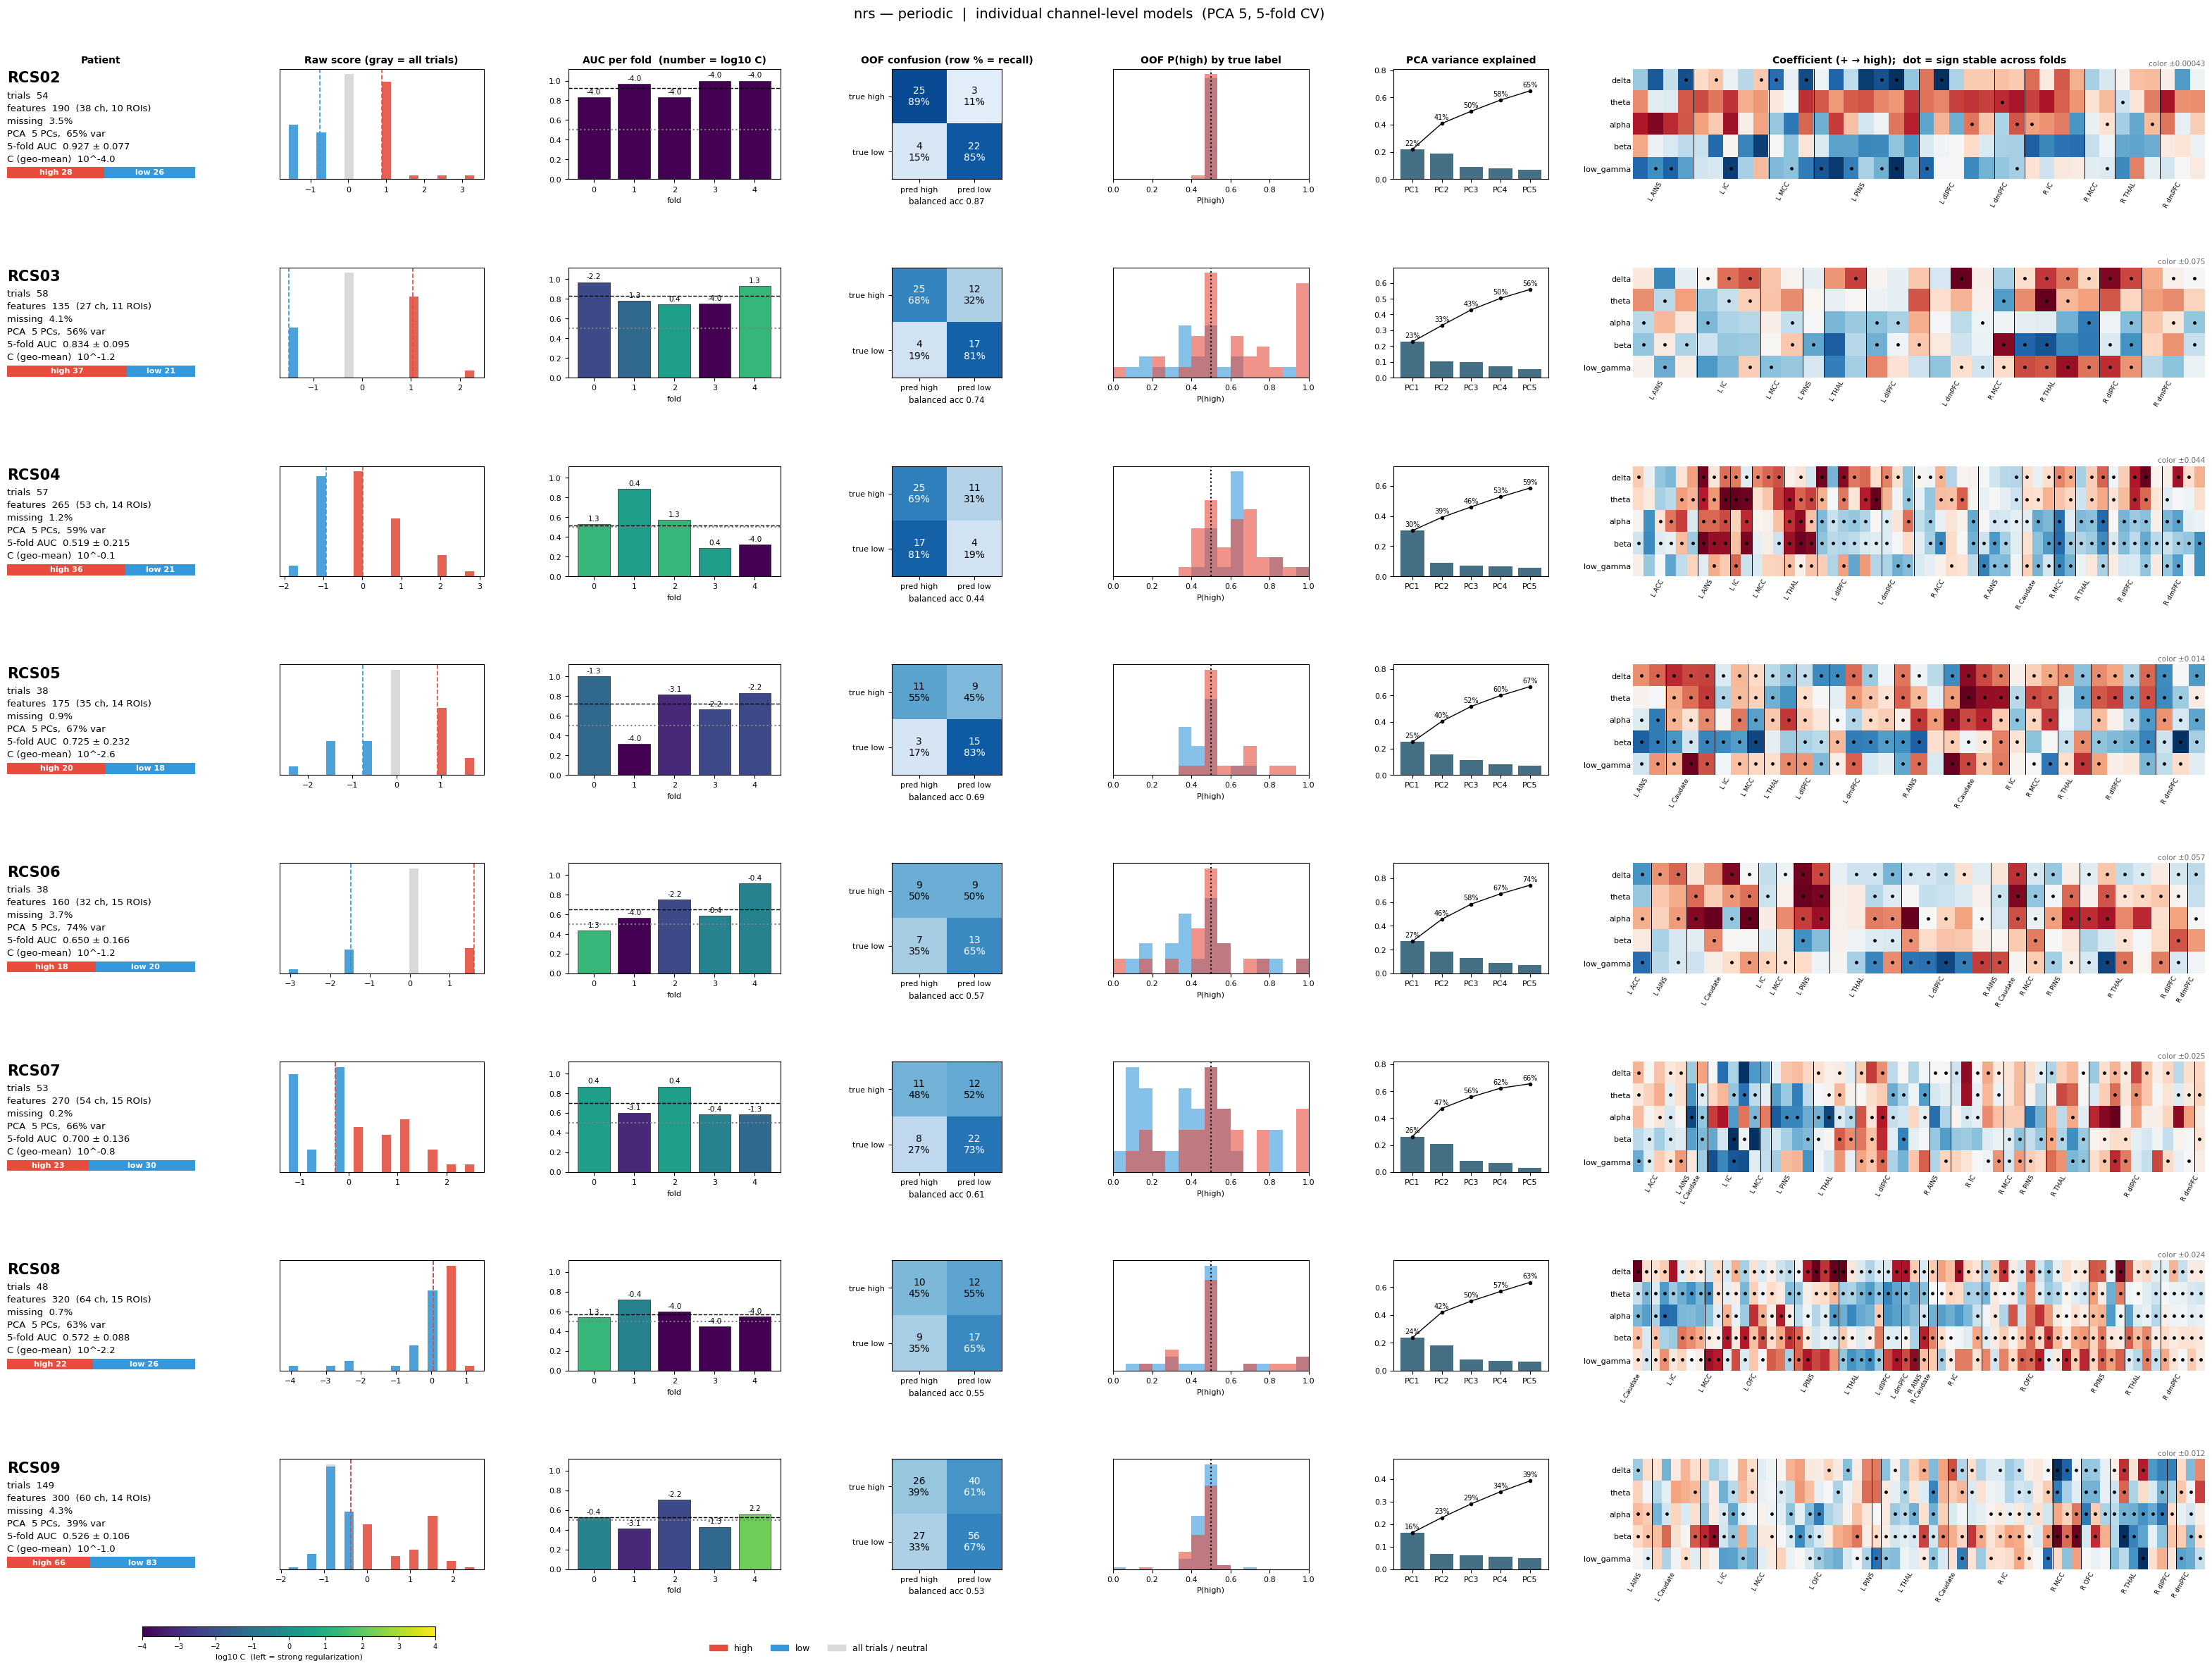

In [15]:
metadir_ind = '/home/hazel/shirvalkar/test-code-hazel/logreg_results_pickle/metadata_individual'
figdir_ind = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/individual_channel_level'

tables = individual_decoding_channel_level('nrs', 'periodic', n_components=5, n_splits=5)
# save_individual_metadata(metadir_ind, tables, 'nrs', 'periodic', dict(n_components=5, n_splits=5))
plot_patient_overview(tables, 'nrs', 'periodic', behavior_table, behavior_configs['nrs'], savedir=None)

# # 全部 model
# for b, cfg in behavior_configs.items():
#     for ft_ in ['periodic', 'aperiodic']:
#         tb = individual_decoding_channel_level(b, ft_)
#         save_individual_metadata(metadir_ind, tb, b, ft_)
#         plot_patient_overview(tb, b, ft_, behavior_table, cfg, savedir=figdir_ind, show=False)

In [20]:
def plot_patient_overview_new(tables, behavior_key, feature_type, behavior_table, config,
                            sort_by=None, ascending=False, stable_thresh=0.6, coef_scale='patient',
                            row_colorbar=None,                                   # NEW
                            bins=20, row_h=2.9, c_range=(-4, 4), savedir=None, show=True):
    if row_colorbar is None:                                                   # NEW: 共用色阶时底部已有一条,不重复画
        row_colorbar = (coef_scale != 'global')
    sel = lambda d: d[(d.behavior == behavior_key) & (d.feature_type == feature_type)]
    P, F, T, S = (sel(tables[k]) for k in ['patient_table', 'fold_table', 'trial_table', 'coef_summary'])
    if sort_by is not None:
        P = P.sort_values(sort_by, ascending=ascending)
    pts, nr = P['ptID'].tolist(), len(P)
    cmapC, normC = plt.get_cmap('viridis'), Normalize(*c_range)
    cm_coef = plt.get_cmap('RdBu_r').copy(); cm_coef.set_bad('#EEEEEE')

    def lim_of(v):
        v = np.abs(np.asarray(v, float)); v = v[np.isfinite(v)]
        return (np.percentile(v, 99) if len(v) else 1.0) or 1.0
    glob_lim = lim_of(S['cv_mean_coef'])

    fig_w, fig_h = 30, row_h * nr + 2.0
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = fig.add_gridspec(nr, 7, width_ratios=[2.3, 2.5, 3.0, 2.0, 1.9, 7.0, 0.6],   # CHANGED: 6 → 7 列
                          hspace=.85, wspace=.35,
                          left=.02, right=.995, top=1 - 1.0 / fig_h, bottom=1.3 / fig_h)
    
    titles = ['Patient', 'Raw score (gray = all trials)', 'AUC per fold (box + dots) / regularization',
              'OOF confusion (row % = recall)', 'PCA variance explained',
              'Coefficient (+ → high);  dot = sign stable across folds', ""]

    for r, pt in enumerate(pts):
        p = P[P.ptID == pt].iloc[0]; f_ = F[(F.ptID == pt) & (F.fold >= 0)].sort_values('fold')
        t, s = T[T.ptID == pt], S[S.ptID == pt]

        a_info, a_score = fig.add_subplot(gs[r, 0]), fig.add_subplot(gs[r, 1])
        sub = gs[r, 2].subgridspec(2, 1, height_ratios=[2.3, 1.0], hspace=1.1)
        a_auc, a_reg = fig.add_subplot(sub[0]), fig.add_subplot(sub[1])
        a_cm, a_pca, a_coef = (fig.add_subplot(gs[r, c]) for c in (3, 4, 5))
        a_cb = fig.add_subplot(gs[r, 6]); a_cb.axis('off')
        if r == 0:
            for a, ti in zip([a_info, a_score, a_auc, a_cm, a_pca, a_coef], titles):
                a.set_title(ti, fontsize=10, fontweight='bold')

        # 1. 基本信息(不含 missing 和 regularization)
        a = a_info; a.set_xlim(0, 1); a.set_ylim(0, 1); a.axis('off')
        a.text(0, .98, pt, fontsize=15, fontweight='bold', va='top')
        info = [f"trials  {p.n_trials}",
                f"features  {p.n_features}  ({p.n_channels} ch, {p.n_rois} ROIs)",
                f"PCA  {p.n_components} PCs,  {p.pca_cum_var:.0%} var" if p.pca_evr is not None else "no PCA",
                f"{p.n_splits}-fold AUC  {p.auc_mean:.3f} ± {p.auc_sd:.3f}"]
        for i, line in enumerate(info):
            a.text(0, .80 - i * .14, line, fontsize=9.5, va='top')
        fh = p.n_high / p.n_trials
        a.barh(.06, fh, height=.1, color=C_HIGH); a.barh(.06, 1 - fh, left=fh, height=.1, color=C_LOW)
        a.text(fh / 2, .06, f'high {p.n_high}', ha='center', va='center', color='white', fontsize=8, fontweight='bold')
        a.text(fh + (1 - fh) / 2, .06, f'low {p.n_low}', ha='center', va='center', color='white', fontsize=8, fontweight='bold')

        # 2. raw score
        allv = behavior_table.loc[behavior_table.ptID == pt, config['column']].dropna().values
        edges = np.linspace(allv.min(), allv.max(), bins + 1)
        a_score.hist(allv, bins=edges, color=C_NEUTRAL)
        for lab, col in [('low', C_LOW), ('high', C_HIGH)]:
            a_score.hist(t.loc[t.label == lab, 'raw_score'].dropna(), bins=edges, color=col, alpha=.85)
        lo, hi = _cutoffs(pt, config, behavior_table)
        a_score.axvline(lo, color=C_LOW, ls='--', lw=1.2); a_score.axvline(hi, color=C_HIGH, ls='--', lw=1.2)
        a_score.set_yticks([]); a_score.tick_params(labelsize=8)

        # 3a. 每折 AUC:横向箱线图 + 每折一个点(颜色 = log10 C)
        aucs = f_['auc'].to_numpy(); logC = np.log10(f_['C'].to_numpy())
        bp = a_auc.boxplot(aucs, vert=False, positions=[0], widths=.55, patch_artist=True, showfliers=False)
        for b in bp['boxes']:
            b.set(facecolor='#EAF1F5', edgecolor='#446F85', lw=1.2)
        plt.setp(bp['medians'], color='k', lw=1.6)
        plt.setp(bp['whiskers'] + bp['caps'], color='#446F85')
        # jit = np.linspace(-.18, .18, len(aucs))                       # 固定的纵向错开,避免点重叠
        jit = np.zeros(len(aucs))
        a_auc.scatter(aucs, jit, c=logC, cmap=cmapC, norm=normC, s=48, edgecolor='k', lw=.5, zorder=3)
        a_auc.axvline(.5, ls=':', c='gray'); a_auc.set_xlim(0, 1); a_auc.set_ylim(-.6, .6)
        a_auc.set_yticks([]); a_auc.tick_params(labelsize=8); a_auc.set_xlabel('AUC', fontsize=8, labelpad=1)
        for sp in ('top', 'right', 'left'):
            a_auc.spines[sp].set_visible(False)

        # 3b. regularization 强弱标尺:每折一个点,菱形 = 几何平均
        a_reg.set_xlim(c_range[0] - .3, c_range[1] + .3); a_reg.set_ylim(-1, 1)
        a_reg.plot(c_range, [0, 0], color='#BBBBBB', lw=3, solid_capstyle='round', zorder=1)
        pos = np.clip(logC, *c_range); 
        # off = np.linspace(-.45, .45, len(logC))
        off = np.zeros(len(logC))
        out = (logC <= c_range[0]) | (logC >= c_range[1])
        a_reg.scatter(pos, off, c=logC, cmap=cmapC, norm=normC, s=48, zorder=3,
                      edgecolor=np.where(out, 'red', 'k'), lw=np.where(out, 1.6, .5))
        gm = float(np.log10(p.C_geomean))
        a_reg.scatter([np.clip(gm, *c_range)], [0], marker='D', s=70, facecolor='white', edgecolor='k', lw=1.1, zorder=4)
        a_reg.text(c_range[0], .98, '← strong reg', ha='left', va='top', fontsize=6.5, color='gray')
        a_reg.text(c_range[1], .98, 'weak →', ha='right', va='top', fontsize=6.5, color='gray')
        a_reg.set_xticks(range(int(c_range[0]), int(c_range[1]) + 1, 2)); a_reg.set_yticks([])
        a_reg.tick_params(labelsize=7.5)
        a_reg.set_xlabel(f'log10 C   (◇ geo-mean {gm:.1f})', fontsize=8, labelpad=1)
        for sp in ('top', 'right', 'left'):
            a_reg.spines[sp].set_visible(False)

        # 4. 混淆矩阵(5 折 out-of-fold 合并)
        cm = confusion_matrix(t['label'], t['pred_label'], labels=['high', 'low'])
        rs = cm.sum(axis=1, keepdims=True)
        pct = np.divide(cm, rs, out=np.zeros(cm.shape, float), where=rs > 0)
        a_cm.imshow(pct, cmap='Blues', vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                a_cm.text(j, i, f'{cm[i, j]}\n{pct[i, j]:.0%}', ha='center', va='center', fontsize=10,
                          color='white' if pct[i, j] > .6 else 'black')
        a_cm.set_xticks([0, 1]); a_cm.set_xticklabels(['pred high', 'pred low'], fontsize=8)
        a_cm.set_yticks([0, 1]); a_cm.set_yticklabels(['true high', 'true low'], fontsize=8)
        a_cm.set_xlabel(f'balanced acc {np.mean(np.diag(pct)):.2f}', fontsize=8.5)

        # 5. PCA 方差
        if p.pca_evr is not None:
            evr = np.asarray(p.pca_evr); x = np.arange(1, len(evr) + 1)
            a_pca.bar(x, evr, color='#446F85'); a_pca.plot(x, np.cumsum(evr), 'o-', color='k', ms=3, lw=1)
            for xi, c_ in zip(x, np.cumsum(evr)):
                a_pca.annotate(f'{c_:.0%}', (xi, c_), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=7)
            a_pca.set_ylim(0, max(np.cumsum(evr)) * 1.25); a_pca.set_xticks(x)
            a_pca.set_xticklabels([f'PC{i}' for i in x], fontsize=7.5); a_pca.tick_params(labelsize=8)
        else:
            a_pca.axis('off')

        # 6. 系数热图
        pairs = sorted(set(zip(s['ch_label'], s['roi'])), key=lambda q: (_roi_key(q[1]), _ch_num(q[0])))
        cols, rois = [q[0] for q in pairs], [q[1] for q in pairs]
        groups = [g for g in BAND_ORDER if g in set(s['feature_group'])]
        pv = lambda v: (s.pivot_table(index='feature_group', columns='ch_label', values=v, aggfunc='mean')
                          .reindex(index=groups, columns=cols))
        M, SC = pv('cv_mean_coef'), pv('sign_consistency')
        lim = glob_lim if coef_scale == 'global' else lim_of(M.to_numpy())
        im = a_coef.imshow(M.values, cmap=cm_coef, vmin=-lim, vmax=lim, aspect='auto', interpolation='none')
        
        yy, xx = np.where(SC.values >= stable_thresh)
        a_coef.scatter(xx, yy, s=6, c='k', zorder=3)
        a_coef.set_yticks(range(len(groups))); a_coef.set_yticklabels([g.replace('_z', '') for g in groups], fontsize=8)
        bounds = [i for i in range(1, len(rois)) if rois[i] != rois[i - 1]]
        for bd in bounds:
            a_coef.axvline(bd - .5, color='k', lw=.7)
        st, en = [0] + bounds, bounds + [len(rois)]
        a_coef.set_xticks([(a_ + b_ - 1) / 2 for a_, b_ in zip(st, en)])
        a_coef.set_xticklabels([rois[a_] for a_ in st], rotation=60, ha='right', fontsize=6.5)
        a_coef.tick_params(length=0, pad=2)
        if coef_scale != 'global':
            a_coef.text(1, 1.03, f'color ±{lim:.2g}', transform=a_coef.transAxes, ha='right', fontsize=7.5, color='dimgray')
        if row_colorbar:                                                        # NEW
            cax = a_cb.inset_axes([0.05, 0.12, 0.30, 0.76])
            cb = fig.colorbar(im, cax=cax)
            cb.set_ticks([-lim, 0, lim])
            cb.ax.set_yticklabels([f'{-lim:.2g}', '0', f'{lim:.2g}'])
            cb.ax.tick_params(labelsize=7, length=2)
            cb.set_label('coef (+ → high)', fontsize=7.5, labelpad=2)
            cb.outline.set_linewidth(.5)
        for sp in a_coef.spines.values():
            sp.set_visible(False)

    if coef_scale == 'global':
        c2 = fig.add_axes([.60, .35 / fig_h, .13, .14 / fig_h])
        fig.colorbar(ScalarMappable(norm=Normalize(-glob_lim, glob_lim), cmap=cm_coef), cax=c2, orientation='horizontal')
        c2.set_xlabel('coefficient (+ → high)', fontsize=8); c2.tick_params(labelsize=7)
    fig.legend(handles=[Patch(color=C_HIGH, label='high'), Patch(color=C_LOW, label='low'),
                        Patch(color=C_NEUTRAL, label='all trials / neutral')],
               loc='lower center', ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(.38, 0))
    p0 = P.iloc[0]
    fig.suptitle(f'{behavior_key} — {feature_type}  |  individual channel-level models  '
                 f'(PCA {int(p0.n_components)}, {int(p0.n_splits)}-fold CV)', fontsize=14, y=.995)
    if savedir:
        Path(savedir).mkdir(parents=True, exist_ok=True)
        fig.savefig(f'{savedir}/{behavior_key}_{feature_type}_patient_overview.png', dpi=200, bbox_inches='tight')
    plt.show() if show else plt.close(fig)
    return fig

In [21]:
metadir_ind = '/home/hazel/shirvalkar/test-code-hazel/logreg_results_pickle/metadata_individual'
figdir_ind = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/per-patient-channellevel'

# tables = individual_decoding_channel_level('nrs', 'periodic', n_components=5, n_splits=5)
# save_individual_metadata(metadir_ind, tables, 'nrs', 'periodic', dict(n_components=5, n_splits=5))
# plot_patient_overview_new(tables, 'nrs', 'periodic', behavior_table, behavior_configs['nrs'], savedir=None)

# 全部 model
for b, cfg in behavior_configs.items():
    for ft_ in ['periodic', 'aperiodic']:
        tb = individual_decoding_channel_level(b, ft_)
        save_individual_metadata(metadir_ind, tb, b, ft_)
        plot_patient_overview_new(tb, b, ft_, behavior_table, cfg, row_colorbar=True, savedir=figdir_ind, show=False)

RCS02: 190 features, 54 trials, 3.5% missing, high/low = 28/26
nrs_periodic pooled model — out-of-sample AUC (5KFold): 0.927 ± 0.077
[0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.6 0.6 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.6 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.6 0.2 0.2 0.6 0.6 0.2 0.6 0.2 0.2
 0.2 0.2 0.6 0.6 0.2 0.2 1.  0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.6 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.6 0.2
 0.6 0.2 0.6 0.2 0.6 0.6 0.2 0.6 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.2
 0.2 0.6 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.6 0.2 0.2 0.2 0.2 0.2]
RCS03: 135 features, 58 trials, 4.1% missing, high/low = 37/21
nrs_periodic pooled model — out-

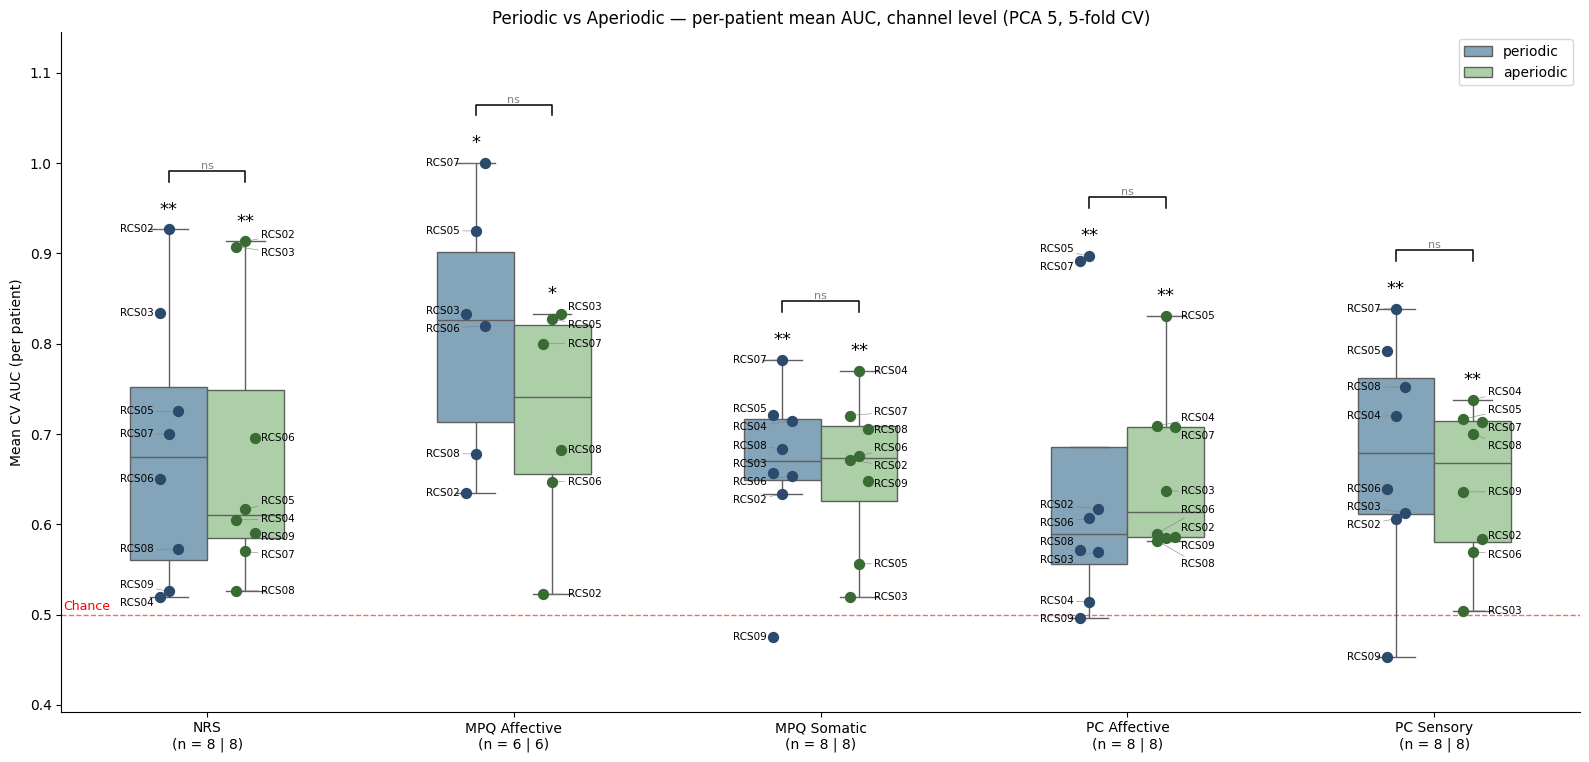

,behavior,feature_type,n,mean_auc,p_raw,p_adj,stars
0,nrs,periodic,8,0.681644,0.003906,0.007812,**
1,nrs,aperiodic,8,0.678124,0.003906,0.007812,**
2,mpq_affective,periodic,6,0.815103,0.015625,0.015625,*
3,mpq_affective,aperiodic,6,0.718779,0.015625,0.015625,*
4,mpq_somatic,periodic,8,0.665120,0.007812,0.009766,**
5,mpq_somatic,aperiodic,8,0.658301,0.003906,0.007812,**
6,affective_pc1,periodic,8,0.645660,0.007812,0.009766,**
7,affective_pc1,aperiodic,8,0.653373,0.003906,0.007812,**
8,sensory_pc1,periodic,8,0.676601,0.007812,0.009766,**
9,sensory_pc1,aperiodic,8,0.645116,0.003906,0.007812,**


,behavior,n_pairs,mean_diff_aperiodic_minus_periodic,p_raw,p_adj,stars
0,nrs,8,-0.003520,0.945312,1.000,ns
1,mpq_affective,6,-0.096324,0.125000,0.625,ns
2,mpq_somatic,8,-0.006819,1.000000,1.000,ns
3,affective_pc1,8,0.007713,0.843750,1.000,ns
4,sensory_pc1,8,-0.031485,0.250000,0.625,ns


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

def _stars(p):
    if p is None or np.isnan(p): return ''
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'ns'

def _spread(y, gap):
    """把过近的标签 y 位置推开,保持原来的上下顺序"""
    y = np.asarray(y, float); order = np.argsort(y); ys = y[order].copy()
    for _ in range(300):
        moved = False
        for i in range(1, len(ys)):
            d = ys[i] - ys[i - 1]
            if d < gap - 1e-9:
                s = (gap - d) / 2; ys[i - 1] -= s; ys[i] += s; moved = True
        if not moved: break
    out = np.empty_like(ys); out[order] = ys
    return out

def compute_auc_tests(df, behavior_order, test='wilcoxon', correct=True):
    d = df.assign(behavior=df['behavior'].astype(str))
    def safe(fn):
        try: return fn()
        except ValueError: return np.nan

    rows = []
    for b in behavior_order:
        for ft in ['periodic', 'aperiodic']:
            x = d[(d.behavior == b) & (d.feature_type == ft)]['auc'].dropna().to_numpy()
            if len(x) < 3: p = np.nan
            elif test == 'wilcoxon': p = safe(lambda: stats.wilcoxon(x - 0.5, alternative='greater').pvalue)
            else: p = stats.ttest_1samp(x, 0.5, alternative='greater').pvalue
            rows.append(dict(behavior=b, feature_type=ft, n=len(x),
                             mean_auc=x.mean() if len(x) else np.nan, p_raw=p))
    chance = pd.DataFrame(rows)

    rows = []
    for b in behavior_order:
        piv = d[d.behavior == b].pivot_table(index='ptID', columns='feature_type', values='auc').dropna()
        if len(piv) >= 3 and {'periodic', 'aperiodic'} <= set(piv.columns):
            diff = piv['aperiodic'] - piv['periodic']
            p = (safe(lambda: stats.wilcoxon(diff).pvalue) if test == 'wilcoxon'
                 else stats.ttest_rel(piv['aperiodic'], piv['periodic']).pvalue)
            md = diff.mean()
        else:
            p, md = np.nan, np.nan
        rows.append(dict(behavior=b, n_pairs=len(piv), mean_diff_aperiodic_minus_periodic=md, p_raw=p))
    paired = pd.DataFrame(rows)

    for t in (chance, paired):                                  # 两个检验族各自做 BH-FDR 校正
        t['p_adj'] = t['p_raw']
        m = t['p_raw'].notna()
        if correct and m.sum() > 1:
            t.loc[m, 'p_adj'] = multipletests(t.loc[m, 'p_raw'], method='fdr_bh')[1]
        t['stars'] = t['p_adj'].map(_stars)
    return chance, paired

def plot_patient_auc_box(df, behavior_order, behavior_labels, test='wilcoxon', correct=True,
                         short_label=False, label_gap=0.02, savepath=None, show=True):
    df = df[df['behavior'].isin(behavior_order)].copy()
    df['behavior'] = pd.Categorical(df['behavior'], categories=behavior_order, ordered=True)
    chance, paired = compute_auc_tests(df, behavior_order, test, correct)
    ch = {(r.behavior, r.feature_type): r for r in chance.itertuples()}
    pr = {r.behavior: r for r in paired.itertuples()}

    fts = ['periodic', 'aperiodic']
    colors = {'periodic': '#7BA7C2', 'aperiodic': '#A8D5A2'}
    dot_colors = {'periodic': '#2C4A6B', 'aperiodic': '#3A6B34'}
    box_width = 0.5
    dodge = box_width / len(fts) / 2                              # seaborn dodge 后每个 box 的半宽 = 中心偏移
    x_pos = {b: i for i, b in enumerate(behavior_order)}
    center = lambda b, ft: x_pos[b] + (-dodge if ft == 'periodic' else dodge)
    max_splits = df['n_splits'].max()
    tops = {(b, ft): g['auc'].max() for (b, ft), g in df.groupby(['behavior', 'feature_type'], observed=True)}

    # 括号高度(先算好,用来定 y 轴上限)
    brk = {b: max(tops.get((b, 'periodic'), 0), tops.get((b, 'aperiodic'), 0)) + 0.065 for b in behavior_order}
    ylo, yhi = min(0.4, df['auc'].min() - 0.06), max(brk.values()) + 0.08

    fig, ax = plt.subplots(figsize=(16, 8))
    sns.boxplot(data=df, x='behavior', y='auc', hue='feature_type', order=behavior_order,
                hue_order=fts, palette=colors, fliersize=0, width=box_width, ax=ax)
    handles, labels = ax.get_legend_handles_labels()
    ax.set_ylim(ylo, yhi)

    # ---- 点 + 标签(periodic 标左侧,aperiodic 标右侧) ----
    for (b, ft), g in df.groupby(['behavior', 'feature_type'], observed=True):
        g = g.sort_values('auc').reset_index(drop=True)
        c = center(b, ft); side = -1 if ft == 'periodic' else 1
        xs = c + np.array([-.03, 0, .03])[np.arange(len(g)) % 3]          # 点在中心附近小幅错开
        ys = g['auc'].to_numpy()
        ly = _spread(ys, label_gap)                                       # 标签竖直方向错开
        lx = c + side * (0.05)                                   # 标签列在 box 外侧
        for i, row in g.iterrows():
            full = row['n_splits'] == max_splits
            ax.scatter(xs[i], ys[i], s=48, zorder=4, linewidths=1.2,
                       facecolor=dot_colors[ft] if full else 'white', edgecolor=dot_colors[ft])
            name = row['ptID'].replace('RCS', '') if short_label else row['ptID']
            ax.annotate(name, xy=(xs[i], ys[i]), xytext=(lx, ly[i]), textcoords='data',
                        ha='right' if side < 0 else 'left', va='center', fontsize=7.5,
                        arrowprops=dict(arrowstyle='-', lw=.4, color='gray', shrinkA=0, shrinkB=2))

    # ---- 对 chance 的星号(每个 box 上方) ----
    for (b, ft), y in tops.items():
        s = ch[(b, ft)].stars
        ax.text(center(b, ft), y + 0.012, s, ha='center', va='bottom',
                fontsize=8 if s == 'ns' else 13, color='gray' if s == 'ns' else 'k')

    # ---- periodic vs aperiodic 括号 ----
    for b in behavior_order:
        x1, x2, yb, tk = center(b, 'periodic'), center(b, 'aperiodic'), brk[b], 0.012
        ax.plot([x1, x1, x2, x2], [yb - tk, yb, yb, yb - tk], color='k', lw=1.1)
        s = pr[b].stars
        ax.text((x1 + x2) / 2, yb, s, ha='center', va='bottom',
                fontsize=8 if s == 'ns' else 13, color='gray' if s == 'ns' else 'k')

    ax.axhline(0.5, color='red', ls='--', lw=1, alpha=.6)
    ax.text(-0.47, 0.505, 'Chance', color='red', fontsize=9)
    n_lab = [f"{behavior_labels[b]}\n(n = {ch[(b, 'periodic')].n} | {ch[(b, 'aperiodic')].n})" for b in behavior_order]
    ax.set_xticks(range(len(behavior_order))); ax.set_xticklabels(n_lab)
    ax.set_ylabel('Mean CV AUC (per patient)'); ax.set_xlabel('')
    ax.set_title('Periodic vs Aperiodic — per-patient mean AUC, channel level (PCA 5, 5-fold CV)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(handles[:2], labels[:2], loc='upper right', frameon=True)

    plt.tight_layout(rect=[0, 0.035, 1, 1])
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show() if show else plt.close(fig)
    return chance, paired

# ---- 调用 ----
tables = load_individual_metadata(metadir_ind)
df = tables['patient_table'].rename(columns={'auc_mean': 'auc'})
behavior_order = ['nrs', 'mpq_affective', 'mpq_somatic', 'affective_pc1', 'sensory_pc1']
behavior_labels = {'nrs': 'NRS', 'mpq_affective': 'MPQ Affective', 'mpq_somatic': 'MPQ Somatic',
                   'affective_pc1': 'PC Affective', 'sensory_pc1': 'PC Sensory'}
chance_df, paired_df = plot_patient_auc_box(
    df, behavior_order, behavior_labels, test='wilcoxon', correct=True,
    savepath=None)
display(chance_df); display(paired_df)